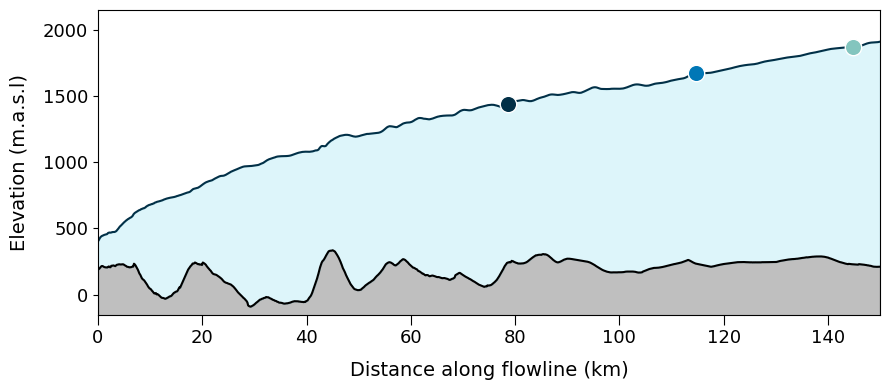

In [ ]:
"""
Figure 1c - Ice surface and bed elevation profile (K-Transect)
Author: Hannah Picton 
Date: 26th March 2026
Description: This notebook plots ice surface and bed elevation data along the K-Transect flowline. 
Ice surface elevation data is extracted from the ArcticDEM v4 mosaic (Porter et al., 2023), whilst bed elevation data is extracted from BedMachine v5 (Morlighem et al., 2022). 
Both files are provided within the 'data' folder of this repository.
"""

# Import libraries 
import os
import pandas as pd
import matplotlib.pyplot as plt

# -- PROVIDE PATH TO ICE SURFACE AND BED ELEVATION DATA --
ice_surface =  pd.read_csv('.../data/flowline_sampled/arcticDEM_v4_sampled_100m.csv') # UPDATE FILEPATH
bed_elevation = pd.read_csv('.../data/flowline_sampled/bedMachine_v5_sampled_150m.csv') # UPDATE FILEPATH

# Data preparation
ice_surface.columns = ["dist_along", "ice_surface"]
bed_elevation.columns = ["dist_along", "bed_elevation"]
ice_surface["dist_km"] = ice_surface["dist_along"] / 1000 # Convert distance from meters to kilometers
bed_elevation["dist_km"] = bed_elevation["dist_along"] / 1000 # Convert distance from meters to kilometers
scatter_points = [(78737.203, 1440.468, "#023047", "LEV5"), (114726.734, 1672.877, "#0077b6", "LEV6"), (144914.750, 1869.695, "#83c5be", "F003")] # Define x and y values for LEV5, LEV6, and F003

# Plot ice surface and bed elevation along the K-Transect flowline. Add scatter points for LEV5, LEV6, and F003.
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(bed_elevation["dist_km"], bed_elevation["bed_elevation"], color="black", label="Bed Elevation")
ax.plot(ice_surface["dist_km"], ice_surface["ice_surface"], color="#023047", label="Surface Elevation")
ax.set_ylabel("Elevation (m.a.s.l)", labelpad=10, fontsize=14)
ax.set_xlabel("Distance along flowline (km)", labelpad=10, fontsize=14)
ax.set_ylim(-150, 2150)
ax.set_xlim(0, bed_elevation["dist_km"].max())
ax.tick_params(axis="y", labelsize=13)
ax.tick_params(axis="x", labelsize=13, length=7)
y1_values = [bed_elevation["bed_elevation"].min() - 100] * len(bed_elevation) 
ax.fill_between(bed_elevation["dist_km"], y1_values, bed_elevation["bed_elevation"], color="gray", alpha=0.5, zorder=1) # Fill area below bed elevation with gray color
bed_interp = bed_elevation.set_index("dist_along").reindex(ice_surface["dist_along"], method="nearest")["bed_elevation"]
ax.fill_between(ice_surface["dist_km"], bed_interp, ice_surface["ice_surface"], color="#90e0ef", alpha=0.3, zorder=1) # Fill area between bed and surface with light blue color
for x_m, y_m, color, label in scatter_points: ax.scatter(x_m/1000, y_m, color=color, s=140, label=label, edgecolors='white', zorder=3) # Add scatter points for LEV5, LEV6, and F003
plt.tight_layout()
plt.show()